In [20]:
# === CELL 1: Setup ===
from __future__ import annotations
import json, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

OUTPUT_DIR = Path("./data/processed")
MODEL_DIR = Path("./models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

Device: cuda


In [21]:
# === CELL 2: Transforms ===
IMG_SIZE = 224
train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

In [22]:
# === CELL 3: Dataset Classes (INLINE — fixes the error) ===
EXCLUDE_COLS = {"ID", "has_cad", "max_stenosis", "num_diseased_vessels"}

def feature_columns(clinical_df):
    return [c for c in clinical_df.columns if c not in EXCLUDE_COLS]


class BaseAngioDataset(Dataset):
    def __init__(self, patient_df, frames_df=None, clinical_df=None,
                 transform=None, aggregate="mean"):
        self.patients = patient_df.reset_index(drop=True)
        self.frames = frames_df
        self.clinical = clinical_df.set_index("ID") if clinical_df is not None else None
        self.transform = transform
        self.aggregate = aggregate
        if self.clinical is not None:
            self.feature_cols = feature_columns(clinical_df)

    def __len__(self):
        return len(self.patients)

    def _load_frames(self, pid):
        subset = self.frames[self.frames["ID"] == str(int(pid))]
        tensors = []
        for path in subset["path"].tolist():
            try:
                img = Image.open(path).convert("RGB")
                tensors.append(self.transform(img) if self.transform
                               else transforms.ToTensor()(img))
            except Exception:
                continue
        return tensors

    def _aggregate(self, tensors):
        if not tensors:
            return torch.zeros(3, IMG_SIZE, IMG_SIZE)
        stack = torch.stack(tensors)
        if self.aggregate == "max":
            return stack.max(dim=0).values
        return stack.mean(dim=0)


class AngioCADDataset(BaseAngioDataset):
    def __getitem__(self, idx):
        row = self.patients.iloc[idx]
        pid = int(row["ID"])
        img = self._aggregate(self._load_frames(pid))
        clinical = self.clinical.loc[pid, self.feature_cols].values.astype(np.float32)
        label = torch.tensor(int(row["has_cad"]), dtype=torch.long)
        return img, torch.from_numpy(clinical), label


class ImageOnlyDataset(BaseAngioDataset):
    def __getitem__(self, idx):
        row = self.patients.iloc[idx]
        img = self._aggregate(self._load_frames(int(row["ID"])))
        label = torch.tensor(int(row["has_cad"]), dtype=torch.long)
        return img, label


class ClinicalOnlyDataset(BaseAngioDataset):
    def __init__(self, patient_df, clinical_df):
        super().__init__(patient_df, frames_df=None, clinical_df=clinical_df)

    def __getitem__(self, idx):
        row = self.patients.iloc[idx]
        pid = int(row["ID"])
        clinical = self.clinical.loc[pid, self.feature_cols].values.astype(np.float32)
        label = torch.tensor(int(row["has_cad"]), dtype=torch.long)
        return torch.from_numpy(clinical), label


In [23]:
# === CELL 4: Focal Loss ===
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0, weight=None):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma
        self.register_buffer("weight", weight if weight is not None else None)

    def forward(self, logits, targets):
        ce = nn.functional.cross_entropy(logits, targets,
                                         weight=self.weight, reduction="none")
        pt = torch.exp(-ce)
        return (self.alpha * (1.0 - pt) ** self.gamma * ce).mean()

In [24]:
# === CELL 5: Model Definitions ===
class ImageEncoder(nn.Module):
    def __init__(self, out_dim=256, pretrained=True):
        super().__init__()
        weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        backbone = models.resnet18(weights=weights)
        feat_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.backbone = backbone
        self.proj = nn.Sequential(
            nn.Linear(feat_dim, out_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
        )
    def forward(self, x):
        return self.proj(self.backbone(x))


class ClinicalEncoder(nn.Module):
    def __init__(self, in_dim, out_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 128), nn.BatchNorm1d(128),
            nn.ReLU(inplace=True), nn.Dropout(0.3),
            nn.Linear(128, out_dim), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.net(x)


class FusionModel(nn.Module):
    def __init__(self, clinical_dim, num_classes=2):
        super().__init__()
        self.img_enc = ImageEncoder(out_dim=256)
        self.clin_enc = ClinicalEncoder(clinical_dim, out_dim=128)
        self.classifier = nn.Sequential(
            nn.Linear(256 + 128, 128),
            nn.ReLU(inplace=True), nn.Dropout(0.4),
            nn.Linear(128, num_classes),
        )
    def forward(self, image, clinical):
        return self.classifier(torch.cat([self.img_enc(image), self.clin_enc(clinical)], dim=1))

In [25]:
# === CELL 6: Load Data ===
clinical_df = pd.read_csv(OUTPUT_DIR / "clinical_features_merged.csv")
frames_df = pd.read_csv(OUTPUT_DIR / "frames_index.csv")
frames_df["ID"] = frames_df["ID"].astype(str)

with open(OUTPUT_DIR / "splits.json") as f: splits = json.load(f)
with open(OUTPUT_DIR / "class_weights.json") as f: class_weights = json.load(f)

train_df = clinical_df[clinical_df["ID"].isin(splits["train"])]
val_df = clinical_df[clinical_df["ID"].isin(splits["val"])]
test_df = clinical_df[clinical_df["ID"].isin(splits["test"])]

BATCH_SIZE = 16
train_ds = AngioCADDataset(train_df, frames_df, clinical_df, transform=train_tfms)
val_ds = AngioCADDataset(val_df, frames_df, clinical_df, transform=eval_tfms)
test_ds = AngioCADDataset(test_df, frames_df, clinical_df, transform=eval_tfms)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f"Train {len(train_ds)} | Val {len(val_ds)} | Test {len(test_ds)}")

Train 255 | Val 46 | Test 76


In [26]:
# === CELL 7: Training Loop ===
def evaluate(model, loader, device):
    model.eval()
    preds, probs, labels = [], [], []
    with torch.no_grad():
        for image, clinical, y in loader:
            image = image.to(device, non_blocking=True)
            clinical = clinical.to(device, non_blocking=True)
            logits = model(image, clinical)
            probs.append(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            preds.append(logits.argmax(dim=1).cpu().numpy())
            labels.append(y.numpy())
    y_true = np.concatenate(labels); y_pred = np.concatenate(preds); y_prob = np.concatenate(probs)
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "auc": float(roc_auc_score(y_true, y_prob)) if len(np.unique(y_true)) > 1 else 0.5,
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
    }


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train(); running_loss = 0.0
    for image, clinical, y in loader:
        image = image.to(device, non_blocking=True)
        clinical = clinical.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(image, clinical), y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        running_loss += loss.item() * image.size(0)
    return running_loss / len(loader.dataset)


EPOCHS = 40
LR = 3e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 6

sample = next(iter(train_loader))
clinical_dim = sample[1].shape[1]

model = FusionModel(clinical_dim=clinical_dim).to(DEVICE)
weight_tensor = torch.tensor([class_weights["0"], class_weights["1"]],
                             dtype=torch.float32).to(DEVICE)
criterion = FocalLoss(alpha=0.25, gamma=2.0, weight=weight_tensor)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

history = []
best_auc, best_epoch, no_improve = -1.0, -1, 0

print("TRAINING STARTED")

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
    scheduler.step()
    val_metrics = evaluate(model, val_loader, DEVICE)
    dt = time.time() - t0

    history.append({
        "epoch": epoch, "train_loss": train_loss,
        "val_auc": val_metrics["auc"], "val_acc": val_metrics["accuracy"],
        "val_f1": val_metrics["f1"], "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "lr": optimizer.param_groups[0]["lr"], "time_s": dt,
    })

    print(f"Epoch {epoch:02d}/{EPOCHS} | Loss {train_loss:.4f} | "
          f"Val AUC {val_metrics['auc']:.4f} | Acc {val_metrics['accuracy']:.4f} | "
          f"F1 {val_metrics['f1']:.4f} | Rec {val_metrics['recall']:.4f} | {dt:.1f}s")

    if val_metrics["auc"] > best_auc + 1e-4:
        best_auc, best_epoch, no_improve = val_metrics["auc"], epoch, 0
        torch.save({
            "epoch": epoch, "model_state": model.state_dict(),
            "clinical_dim": clinical_dim, "best_auc": best_auc,
        }, MODEL_DIR / "best_fusion_model.pt")
        print(f"  -> new best AUC {best_auc:.4f}, saved")
    else:
        no_improve += 1
        if no_improve >= PATIENCE:
            print(f"  -> no improvement for {PATIENCE} epochs, early stop")
            break

print(f"Training finished. Best AUC {best_auc:.4f} at epoch {best_epoch}.")


TRAINING STARTED
Epoch 01/40 | Loss 0.0487 | Val AUC 0.4583 | Acc 0.2609 | F1 0.1053 | Rec 0.0556 | 88.8s
  -> new best AUC 0.4583, saved
Epoch 02/40 | Loss 0.0442 | Val AUC 0.5167 | Acc 0.2609 | F1 0.2273 | Rec 0.1389 | 30.0s
  -> new best AUC 0.5167, saved
Epoch 03/40 | Loss 0.0326 | Val AUC 0.4944 | Acc 0.4348 | F1 0.5185 | Rec 0.3889 | 28.7s
Epoch 04/40 | Loss 0.0379 | Val AUC 0.7167 | Acc 0.5217 | F1 0.6071 | Rec 0.4722 | 30.6s
  -> new best AUC 0.7167, saved
Epoch 05/40 | Loss 0.0336 | Val AUC 0.6083 | Acc 0.4348 | F1 0.4583 | Rec 0.3056 | 30.0s
Epoch 06/40 | Loss 0.0302 | Val AUC 0.6722 | Acc 0.6087 | F1 0.6897 | Rec 0.5556 | 29.1s
Epoch 07/40 | Loss 0.0317 | Val AUC 0.7417 | Acc 0.3696 | F1 0.3256 | Rec 0.1944 | 28.4s
  -> new best AUC 0.7417, saved
Epoch 08/40 | Loss 0.0280 | Val AUC 0.7417 | Acc 0.4565 | F1 0.5098 | Rec 0.3611 | 30.5s
Epoch 09/40 | Loss 0.0194 | Val AUC 0.7444 | Acc 0.8478 | F1 0.9041 | Rec 0.9167 | 31.9s
  -> new best AUC 0.7444, saved
Epoch 10/40 | Loss 0.0

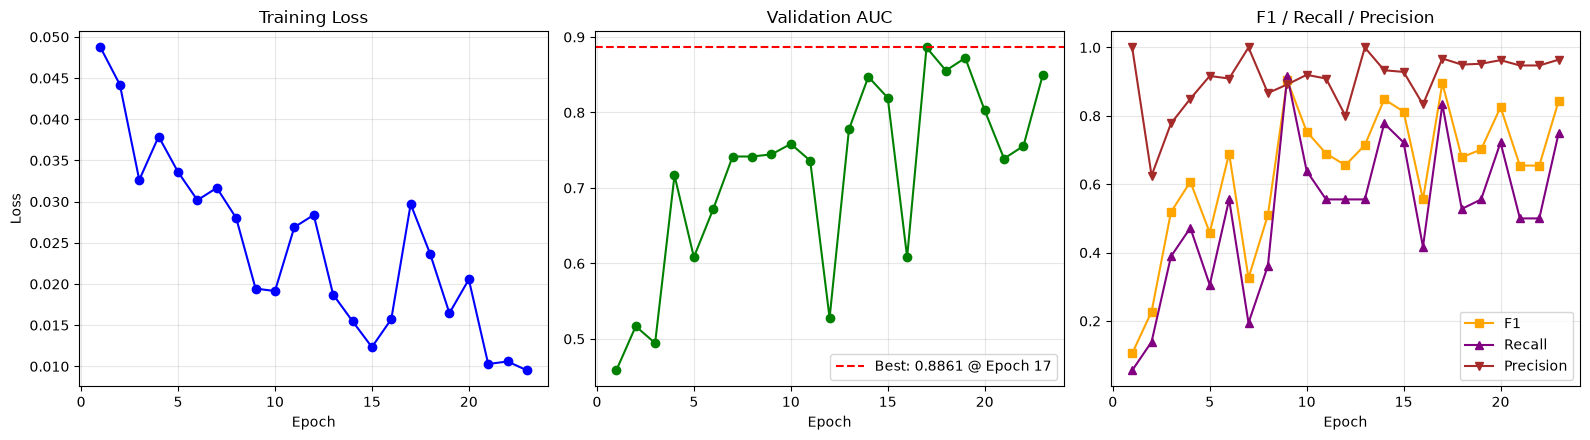

FINAL TRAINING SUMMARY
Best Val AUC      : 0.8861 (Epoch 17)
Best Val F1       : 0.9041
Best Val Recall   : 0.9167
Best Val Precision: 1.0000
Total epochs run  : 23
Model saved at    : models\best_fusion_model.pt


In [27]:
# === CELL 8: Post-Training Analysis ===
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Loss
axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", color="blue")
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3)

# AUC with best highlighted
axes[1].plot(history_df["epoch"], history_df["val_auc"], marker="o", color="green")
axes[1].axhline(y=best_auc, color="red", linestyle="--",
                label=f"Best: {best_auc:.4f} @ Epoch {best_epoch}")
axes[1].set_title("Validation AUC")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(alpha=0.3)

# F1 / Recall / Precision
axes[2].plot(history_df["epoch"], history_df["val_f1"], marker="s",
             label="F1", color="orange")
axes[2].plot(history_df["epoch"], history_df["val_recall"], marker="^",
             label="Recall", color="purple")
axes[2].plot(history_df["epoch"], history_df["val_precision"], marker="v",
             label="Precision", color="brown")
axes[2].set_title("F1 / Recall / Precision")
axes[2].set_xlabel("Epoch")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(MODEL_DIR / "training_curves.png", dpi=200)
plt.show()

# Save history CSV
history_df.to_csv(MODEL_DIR / "training_history.csv", index=False)

print("=" * 70)
print("FINAL TRAINING SUMMARY")
print("=" * 70)
print(f"Best Val AUC      : {history_df['val_auc'].max():.4f} "
      f"(Epoch {history_df['val_auc'].idxmax() + 1})")
print(f"Best Val F1       : {history_df['val_f1'].max():.4f}")
print(f"Best Val Recall   : {history_df['val_recall'].max():.4f}")
print(f"Best Val Precision: {history_df['val_precision'].max():.4f}")
print(f"Total epochs run  : {len(history_df)}")
print(f"Model saved at    : {MODEL_DIR / 'best_fusion_model.pt'}")
print("=" * 70)